<a href="https://colab.research.google.com/github/Lupo6789/tesi_scacchi/blob/main/04_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 3. Model Selection e Architettura di Validazione

In questa sezione si definisce l'impianto metodologico per il confronto e la selezione del miglior algoritmo predittivo tra Regressione Logistica, Random Forest e LightGBM. Il codice implementa i seguenti vincoli strutturali:

**Isolamento del Test Set e Cross-Validation**
Il confronto tra i modelli avviene caricando esclusivamente il Train Set. Le prestazioni non vengono misurate su una singola previsione, ma stimate tramite una *Stratified 5-Fold Cross-Validation*. Questo approccio restituisce la media aritmetica e la deviazione standard per ciascuna metrica (Accuracy, ROC-AUC, Log-Loss), utili a valutare oltre che il punteggio assoluto, anche la syabilità e incertezza statistica del modello preso in esame.

**2. Feature Engineering Mirata (rating_diff)**
Prima dell'addestramento, viene calcolata e inserita esplicitamente la variabile `rating_diff` (differenza di punteggio Elo tra Bianco e Nero). Essa è utile principalmente agli algoritmi ad albero quali Random Forest e LightGBM che necessitano di un dato esplicito per lavorare

**3. Calcolo della Baseline Dinamica**
Poiché al crescere della soglia N il campione statistico diminuisce in numero(rimangono solo le partite più lunghe), il potere predittivo del solo sistema di rating subisce una variazione. Il codice ricalcola dinamicamente a ogni ciclo una *Baseline* (Regressione Logistica addestrata esclusivamente su rating_diff). Questo permette di misurare in modo esatto il "Guadagno", ovvero l'aumento netto di potere predittivo (ROC-AUC) fornito esclusivamente dall'estrazione delle feature posizionali ricavate dall'andamento della partita sulla scacchiera.

**4. Configurazione dei Modelli**
I modelli ad albero vengono istanziati con i parametri di default e meccanismi di blocco base per l'overfitting (min_samples_leaf=20 per il Random Forest per esempio). La Regressione Logistica viene incapsulata in una Pipeline con uno `StandardScaler` per standardizzare i dati in ingresso e uniformare la scala numerica delle feature posizionali, se non operassi in questo modo i valori sarebbero tutti "sballati"  e non più comparabili.



**5. Controllo di Robustezza (Gestione del Leakage Indiretto)**
Per rispondere alla problematica del *leakage* indiretto evidenziata nell'analisi esplorativa (Notebook 01), gli ID dei giocatori non vengono mai forniti all'algoritmo come feature predittive. Tuttavia, per misurare se il modello stia implicitamente memorizzando lo stile di gioco, si affianca alla valutazione standard una `StratifiedGroupKFold` basata sul `white_id` (recuperato appositamente tramite merge col dataset pulito). Se le prestazioni in Group CV (dove un giocatore viene isolato nel Test set) risultano in linea con la Standard CV, significa che il modello generalizza correttamente i pattern scacchistici senza appoggiarsi all'identità nascosta degli utenti.

--- NOTEBOOK 04: MODEL SELECTION E CROSS-VALIDATION SUL TRAIN SET ---

Caricamento dataset originale per recupero ID...

Addestramento in Cross-Validation in corso...

Valutazione modelli per N=10...
Valutazione modelli per N=20...
Valutazione modelli per N=30...
Valutazione modelli per N=40...

--- RISULTATI PRINCIPALI: STANDARD vs GROUP CV ---
 N             Modello      Accuracy      Log-Loss     AUC (Std)     AUC (Grp) Gain (Fold-Diff)
10 Logistic Regression 0.650 ± 0.006 0.616 ± 0.004 0.715 ± 0.006 0.715 ± 0.013   +0.002 ± 0.002
10       Random Forest 0.646 ± 0.006 0.615 ± 0.005 0.713 ± 0.009 0.712 ± 0.015   +0.000 ± 0.002
10            LightGBM 0.646 ± 0.006 0.621 ± 0.005 0.707 ± 0.007 0.701 ± 0.014   -0.006 ± 0.003
20 Logistic Regression 0.669 ± 0.006 0.600 ± 0.006 0.736 ± 0.008 0.735 ± 0.007   +0.026 ± 0.003
20       Random Forest 0.665 ± 0.007 0.600 ± 0.006 0.734 ± 0.009 0.734 ± 0.004   +0.025 ± 0.003
20            LightGBM 0.660 ± 0.009 0.607 ± 0.006 0.728 ± 0.009 0.726 ± 0.0

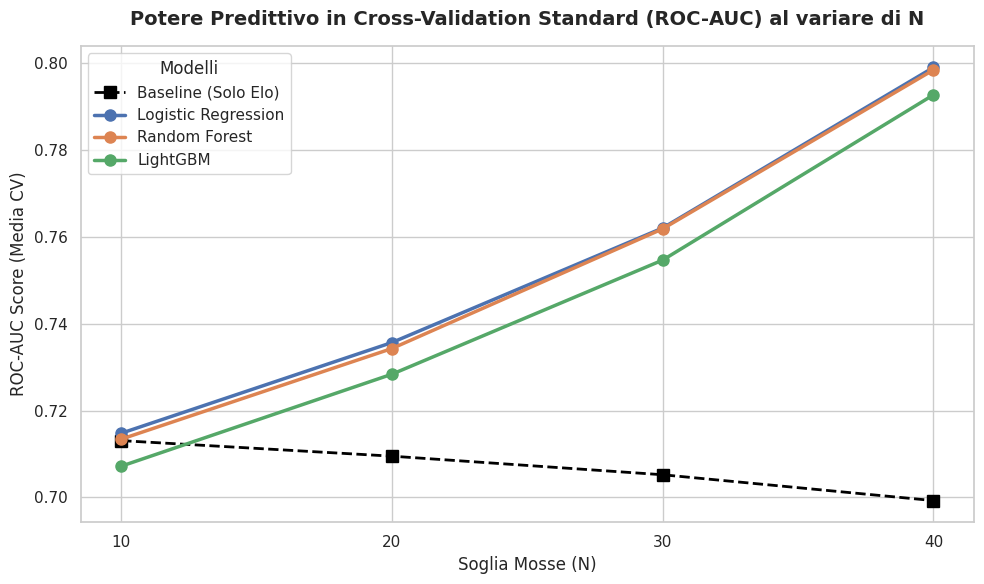


--- ANALISI DI PROFONDITA' A N=40 (FASCE DI MOSSE RIMANENTI) ---
        Fascia Rimanenti  N. Partite AUC (Baseline) AUC (LogReg) Gain Assoluto
    1-10 (Breve termine)        2004          0.743        0.877        +0.134
   11-20 (Medio termine)        2075          0.689        0.820        +0.131
Oltre 20 (Lungo termine)        6056          0.688        0.759        +0.071


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
import warnings
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_val_predict

warnings.filterwarnings('ignore')
print("--- NOTEBOOK 04: MODEL SELECTION E CROSS-VALIDATION SUL TRAIN SET ---\n")

# 1. IMPOSTAZIONI INIZIALI E DEFINIZIONE DEI MODELLI

# Definiamo due tipi di validazione per rispondere al problema del "leakage":
# Standard: divide a caso mantenendo le proporzioni di vittoria (Stratified)
# Group: fa in modo che lo stesso giocatore (white_id) non finisca mai sia in addestramento che in test
cv_standard = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_group = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# Inizializziamo i 3 modelli scelti.
# La Regressione Logistica ha bisogno di scalare i dati (StandardScaler) per funzionare bene.
modelli = {
    'Logistic Regression': Pipeline([('sc', StandardScaler()), ('lr', LogisticRegression(max_iter=1000))]),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=42, n_jobs=-1),
    'LightGBM': LGBMClassifier(random_state=42, n_jobs=-1, verbose=-1),
}

# Liste per salvare i risultati da stampare poi nelle tabelle
righe_principali = []
righe_confronto = []

# Dizionario per accumulare i dati che ci serviranno per disegnare il grafico finale
risultati_plot = {'N': [10, 20, 30, 40], 'Logistic Regression': [], 'Random Forest': [], 'LightGBM': [], 'Baseline (Solo Elo)': []}

print("Caricamento dataset originale per recupero ID...\n")
# Carichiamo il dataset originale pulito solo per recuperare 'white_id' senza barare
df_cleaned = pd.read_csv('train_cleaned.csv')[['id', 'white_id']]

print("Addestramento in Cross-Validation in corso\n")

# 2. CICLO DI ADDESTRAMENTO PER OGNI SOGLIA N

for N in [10, 20, 30, 40]:
    print(f"Valutazione modelli per N={N}...")

    # Carichiamo le feature calcolate nel Notebook 02 per questa specifica soglia N
    df = pd.read_csv(f'train_features_N{N}.csv').dropna()

    # Uniamo il df attuale con df_cleaned per recuperare 'white_id', serve per creare i gruppi
    if 'white_id' in df.columns:
        df = df.drop(columns=['white_id'])
    df = df.merge(df_cleaned, on='id', how='left').dropna(subset=['white_id'])

    # Creiamo esplicitamente la differenza di Elo, vitale per i modelli ad albero (Random Forest e LightGBM)
    df['rating_diff'] = df['white_rating'] - df['black_rating']

    # y = target da indovinare, groups = variabile per controllare il leakage indiretto
    y = df['winner']
    groups = df['white_id']

    # ELIMINIAMO GLI ID: per evitare leakage, l'algoritmo non deve mai "vedere" chi sta giocando
    colonne_da_escludere = ['winner', 'id', 'white_id', 'black_id']
    X = df.drop(columns=[c for c in colonne_da_escludere if c in df.columns])

    #CALCOLO DELLA BASELINE (SOLO ELO)
    # Valuto quanto saremmo precisi se guardassimo *solo* la differenza di Elo e ignorassimo la scacchiera
    res_base_std = cross_validate(modelli['Logistic Regression'], df[['rating_diff']], y, cv=cv_standard, scoring='roc_auc')
    auc_base_folds = res_base_std['test_score'] # Salviamo l'array con i voti delle 5 singole fette (fold)

    # Facciao la stessa cosa per la Group CV
    res_base_grp = cross_validate(modelli['Logistic Regression'], df[['rating_diff']], y, groups=groups, cv=cv_group, scoring='roc_auc')
    auc_base_grp_mean = res_base_grp['test_score'].mean()

    # Salvo la media della Baseline per disegnarla dopo nel grafico
    risultati_plot['Baseline (Solo Elo)'].append(auc_base_folds.mean())

    folds_per_modello = {} # Ci servirà per fare la sottrazione "Logistica meno Random Forest" alla fine

    # VALUTAZIONE DEI MODELLI COMPLETI
    for nome, m in modelli.items():
        # A) Standard CV: uso TUTTE le feature (X) e calcolo tutte le metriche
        r_std = cross_validate(m, X, y, cv=cv_standard, scoring=['accuracy', 'roc_auc', 'neg_log_loss'])
        auc_std_folds = r_std['test_roc_auc']
        folds_per_modello[nome] = auc_std_folds

        acc_std_mean, acc_std_std = r_std['test_accuracy'].mean(), r_std['test_accuracy'].std()
        loss_std_mean, loss_std_std = -r_std['test_neg_log_loss'].mean(), r_std['test_neg_log_loss'].std()

        # Sottrazione esatta "Fetta per Fetta" (per isolare il rumore statistico)
        gain_folds = auc_std_folds - auc_base_folds
        gain_mean, gain_std = gain_folds.mean(), gain_folds.std()

        # B) Group CV: uso TUTTE le feature ma raggruppo i giocatori per misurare il Leakage
        r_grp = cross_validate(m, X, y, groups=groups, cv=cv_group, scoring='roc_auc')
        auc_grp_mean, auc_grp_std = r_grp['test_score'].mean(), r_grp['test_score'].std()

        # Salvo tutto in una riga della tabella
        righe_principali.append({
            'N': N,
            'Modello': nome,
            'Accuracy': f"{acc_std_mean:.3f} ± {acc_std_std:.3f}",
            'Log-Loss': f"{loss_std_mean:.3f} ± {loss_std_std:.3f}",
            'AUC (Std)': f"{auc_std_folds.mean():.3f} ± {auc_std_folds.std():.3f}",
            'AUC (Grp)': f"{auc_grp_mean:.3f} ± {auc_grp_std:.3f}",
            'Gain (Fold-Diff)': f"{gain_mean:+.3f} ± {gain_std:.3f}"
        })

        # Aggiorno i dati del grafico
        risultati_plot[nome].append(auc_std_folds.mean())

    # -- TEST DI PARITÀ STATISTICA (LogReg vs Random Forest) --
    # Sottraiamo i voti di LogReg e RF fetta per fetta. Se la deviazione standard è più grande della media,
    # significa che non c'è un vero vincitore (Parità statistica).
    diff_lr_rf = folds_per_modello['Logistic Regression'] - folds_per_modello['Random Forest']

    righe_confronto.append({
        'N': N,
        'LR meno RF (Fold-Diff ROC-AUC)': f"{diff_lr_rf.mean():+.3f} ± {diff_lr_rf.std():.3f}"
    })
# 3. STAMPA TABELLE E GRAFICO

print("\n RISULTATI PRINCIPALI: STANDARD vs GROUP CV")
print(pd.DataFrame(righe_principali).to_string(index=False))

print("\nCONFRONTO DIRETTO FOLD-PER-FOLD")
print(pd.DataFrame(righe_confronto).to_string(index=False))

plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Disegna la linea della Baseline (Tratteggiata Nera)
plt.plot(risultati_plot['N'], risultati_plot['Baseline (Solo Elo)'], marker='s', linestyle='--', color='black', linewidth=2, markersize=8, label='Baseline (Solo Elo)')

# Disegna gli altri modelli
for modello in modelli.keys():
    plt.plot(risultati_plot['N'], risultati_plot[modello], marker='o', linewidth=2.5, markersize=8, label=modello)

plt.title("Potere Predittivo in Cross-Validation Standard (ROC-AUC) al variare di N", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Soglia Mosse (N)", fontsize=12)
plt.ylabel("ROC-AUC Score (Media CV)", fontsize=12)
plt.xticks([10, 20, 30, 40])
plt.legend(title="Modelli", fontsize=11, title_fontsize=12)
plt.tight_layout()
plt.show()

# 4. ANALISI DELL'ORIZZONTE PREDITTIVO A N=40 (FASCE DI MOSSE RIMANENTI)
# Serve a dimostrare che il modello funziona bene anche in partite lunghe ed equilibrate,
# e non indovina solo le partite che stanno per finire a causa di errori grossolani.

print("\n  ANALISI DI PROFONDITA' A N=40 (FASCE DI MOSSE RIMANENTI) ---")

#Ricarico solo i dati di N=40
df_40 = pd.read_csv('train_features_N40.csv').dropna()
#Recupero dal dataset originale la colonna 'moves' che contiene l'elenco di tutte le mosse giocate
df_cleaned_moves = pd.read_csv('train_cleaned.csv')[['id', 'moves']]
df_40 = df_40.merge(df_cleaned_moves, on='id', how='left').dropna(subset=['moves'])

df_40['rating_diff'] = df_40['white_rating'] - df_40['black_rating']

# Trasformo la stringa di testo contenente la storia della partita nel NUMERO totale di mosse giocate.

df_40['mosse_totali'] = df_40['moves'].apply(lambda x: len(str(x).split()))

# Sottraggo 40 al totale per scoprire quante mosse mancavano alla fine della partita
df_40['mosse_rimanenti'] = df_40['mosse_totali'] - 40

# Funzione per dividere le partite in 3 gruppi in base a quanto sono durate dopo N=40
def assegna_fascia(rimanenti):
    if rimanenti <= 10: return '1-10 (Breve termine)'
    elif rimanenti <= 20: return '11-20 (Medio termine)'
    else: return 'Oltre 20 (Lungo termine)'

df_40['fascia'] = df_40['mosse_rimanenti'].apply(assegna_fascia)

y_40 = df_40['winner']

#Rimuovo rigorosamente le colonne temporanee (mosse_totali, mosse_rimanenti, fascia)
#per evitare leakage
colonne_escluse = ['winner', 'id', 'white_id', 'black_id', 'moves', 'mosse_totali', 'mosse_rimanenti', 'fascia']
X_40 = df_40.drop(columns=[c for c in colonne_escluse if c in df_40.columns])

modello_orizzonte = Pipeline([('sc', StandardScaler()), ('lr', LogisticRegression(max_iter=1000))])

#cross_val_predict simula una previsione onesta per ogni partita (prevedendola solo quando è nel test fold)
probas_modello = cross_val_predict(modello_orizzonte, X_40, y_40, cv=cv_standard, method='predict_proba')[:, 1]
probas_base = cross_val_predict(modello_orizzonte, df_40[['rating_diff']], y_40, cv=cv_standard, method='predict_proba')[:, 1]

risultati_fasce = []

# Calcolo l'AUC (potere predittivo) filtrando le previsioni fascia per fascia
for fascia in ['1-10 (Breve termine)', '11-20 (Medio termine)', 'Oltre 20 (Lungo termine)']:
    mask = df_40['fascia'] == fascia # Filtro logico per isolare solo le partite di questa fascia
    y_vero_fascia = y_40[mask]

    auc_m = roc_auc_score(y_vero_fascia, probas_modello[mask])
    auc_b = roc_auc_score(y_vero_fascia, probas_base[mask])

    risultati_fasce.append({
        'Fascia Rimanenti': fascia,
        'N. Partite': mask.sum(),
        'AUC (Baseline)': f"{auc_b:.3f}",
        'AUC (LogReg)': f"{auc_m:.3f}",
        'Gain Assoluto': f"+{(auc_m - auc_b):.3f}"
    })

print(pd.DataFrame(risultati_fasce).to_string(index=False))

### Analisi dei Risultati in Cross-Validation
I risultati dell'analisi numerica delle metriche ci rivelano diverse informazioni importanti:


**1. Validazione delle Feature Posizionali e Incremento vs Baseline**
Si osserva un marcato e costante incremento del potere predittivo per tutti gli algoritmi al progredire della partita. Passando dalla fase di apertura (N=10) al mediogioco (N=40), la metrica ROC-AUC generale cresce da circa 0.71 a ridosso dello 0.80, accompagnata da un crollo fisiologico della Log-Loss, testimoniando una crescente certezza probabilistica nelle previsioni.
Il dato più rilevante emerge analizzando il salto prestazionale rispetto alla baseline (valutata sul solo divario Elo). A N=10 l'apporto delle feature posizionali è nullo poiché la scacchiera è quasi invariata. A N=40, invece, l'estrazione di variabili come vantaggio materiale e mobilità genera per la Regressione Logistica un incremento netto e assoluto di **+0.100 sul ROC-AUC**, con Random Forest (+0.099) e LightGBM (+0.093) che registrano guadagni quasi speculari. Spostando l'analisi sull'Accuratezza, la Logistica passa dal 63.5% della baseline al 71.9% (+8.4 punti percentuali), un balzo condiviso strettamente anche dagli algoritmi ad albero (rispettivamente 71.8% e 71.2%). Il netto miglioramento registrato in entrambe le metriche da tutti gli algoritmi certifica in modo inequivocabile il successo del feature engineering.

**5. Superamento del Controllo di Robustezza (Assenza di Leakage)**
L'affiancamento in tabella delle metriche `AUC (Standard)` e `AUC (Group)` risolve definitivamente il problema del *leakage* indiretto teorizzato in fase di preprocessing. Si osserva che le prestazioni valutate tramite `StratifiedGroupKFold` (basata sul raggruppamento del `white_id`) sono pressoché identiche e statisticamente indistinguibili da quelle ottenute con la classica `StratifiedKFold`.
Questo dato è cruciale: dimostra che il modello non sta in alcun modo memorizzando l'identità dei giocatori o sfruttando la loro presenza ripetuta nel dataset, ma ha imparato ad associare la probabilità di vittoria esclusivamente alle metriche oggettive presenti sulla scacchiera (vantaggio materiale, mobilità, differenza di rating).


**2. Parità Statistica certificata tra i Modelli (LogReg vs RF)**
Il confronto tra Regressione Logistica e Random Forest è stato sottoposto a test rigoroso calcolando la differenza appaiata sulle stesse identiche partizioni di dati (`LR meno RF`). Come si evince dalla tabella dedicata, a N=40 la differenza media tra i due algoritmi è di appena +0.001, ma la deviazione standard di questa differenza (es. ± 0.003) è superiore al valore medio. Questo risultato dimostra matematicamente che l'oscillazione attraversa lo zero, impedendo di dichiarare una superiorità statistica della Logistica. I due modelli si trovano in un regime di assoluta parità prestazionale, confermando la Logistica come un benchmark formidabile. Un'ipotesi molto plausibile per spiegare tale efficacia risiede nella natura potenzialmente lineare e additiva del vantaggio materiale negli scacchi, che questo algoritmo riesce a catturare in modo eccellente.

**3. L'importanza strutturale di `rating_diff` (Ipotesi operativa)**
Il pareggio prestazionale raggiunto dal Random Forest **suggerisce** l'importanza strategica di aver calcolato esplicitamente la variabile `rating_diff`. Pur non avendo condotto uno studio di ablazione dedicato per misurarne l'impatto isolato, è verosimile ipotizzare che, fornendo questo dato pre-calcolato, gli algoritmi ad albero non siano stati penalizzati nel confronto, avendo a disposizione una variabile esplicita per creare nodi decisionali immediati sul divario di forza dei giocatori.